In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để gọi module từ src
sys.path.append(str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from src.config import NUMERICAL_COLS, CATEGORICAL_COLS, FIGURES_DIR
from src.data_utils import load_raw_data, load_decoded_data

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted")

df_raw = load_raw_data()
df_eda = load_decoded_data()

print(f"1. Kích thước tập dữ liệu: {df_raw.shape[0]} mẫu, {df_raw.shape[1]} cột")
print(f"2. Số lượng dòng trùng lặp: {df_raw.duplicated().sum()}")
print(f"3. Tổng số giá trị thiếu (NaN): {df_raw.isnull().sum().sum()}")
print("\n4. Thông tin kiểu dữ liệu:")
display(df_raw.dtypes.value_counts())
display(df_eda.head())

1. Kích thước tập dữ liệu: 1000 mẫu, 21 cột
2. Số lượng dòng trùng lặp: 0
3. Tổng số giá trị thiếu (NaN): 0

4. Thông tin kiểu dữ liệu:


str      13
int64     8
Name: count, dtype: int64

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target,target_label
0,< 0 DM,6,Critical / other credits,Radio/television,1169,Unknown / no savings,>= 7 years,4,Male: single,None,...,67,None,Own,2,Skilled employee,1,Yes (registered),Yes,0,Good (0)
1,0 - 200 DM,48,Existing paid duly,Radio/television,5951,< 100 DM,1 - 4 years,2,Female: div/sep/mar,None,...,22,None,Own,1,Skilled employee,1,None,Yes,1,Bad (1)
2,No checking account,12,Critical / other credits,Education,2096,< 100 DM,4 - 7 years,2,Male: single,None,...,49,None,Own,1,Unskilled resident,2,None,Yes,0,Good (0)
3,< 0 DM,42,Existing paid duly,Furniture/equipment,7882,< 100 DM,4 - 7 years,2,Male: single,Guarantor,...,45,None,For free,1,Skilled employee,2,None,Yes,0,Good (0)
4,< 0 DM,24,Delay in past,Car (new),4870,< 100 DM,1 - 4 years,3,Male: single,None,...,53,None,For free,2,Skilled employee,2,None,Yes,1,Bad (1)


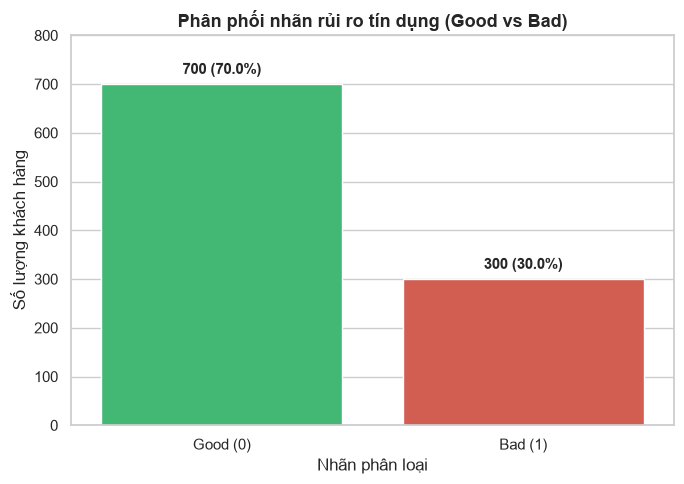

In [2]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_eda, x="target_label", hue="target_label", palette=["#2ecc71", "#e74c3c"], legend=False)

total = len(df_eda)
for p in ax.patches:
    count = int(p.get_height())
    pct = 100 * count / total
    ax.annotate(f"{count} ({pct:.1f}%)", (p.get_x() + p.get_width() / 2., count),
                ha="center", va="bottom", fontsize=11, fontweight="bold", xytext=(0, 5), textcoords="offset points")

plt.title("Phân phối nhãn rủi ro tín dụng (Good vs Bad)", fontsize=13, fontweight="bold")
plt.xlabel("Nhãn phân loại")
plt.ylabel("Số lượng khách hàng")
plt.ylim(0, 800)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_target_distribution.png", dpi=300)
plt.show()

Thống kê mô tả 7 đặc trưng số:


,count,mean,std,min,25%,50%,75%,max,skewness
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0,1.094184
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0,1.949628
installment_commitment,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0,-0.531348
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0,-0.272570
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0,1.020739
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0,1.272576
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0,1.909445


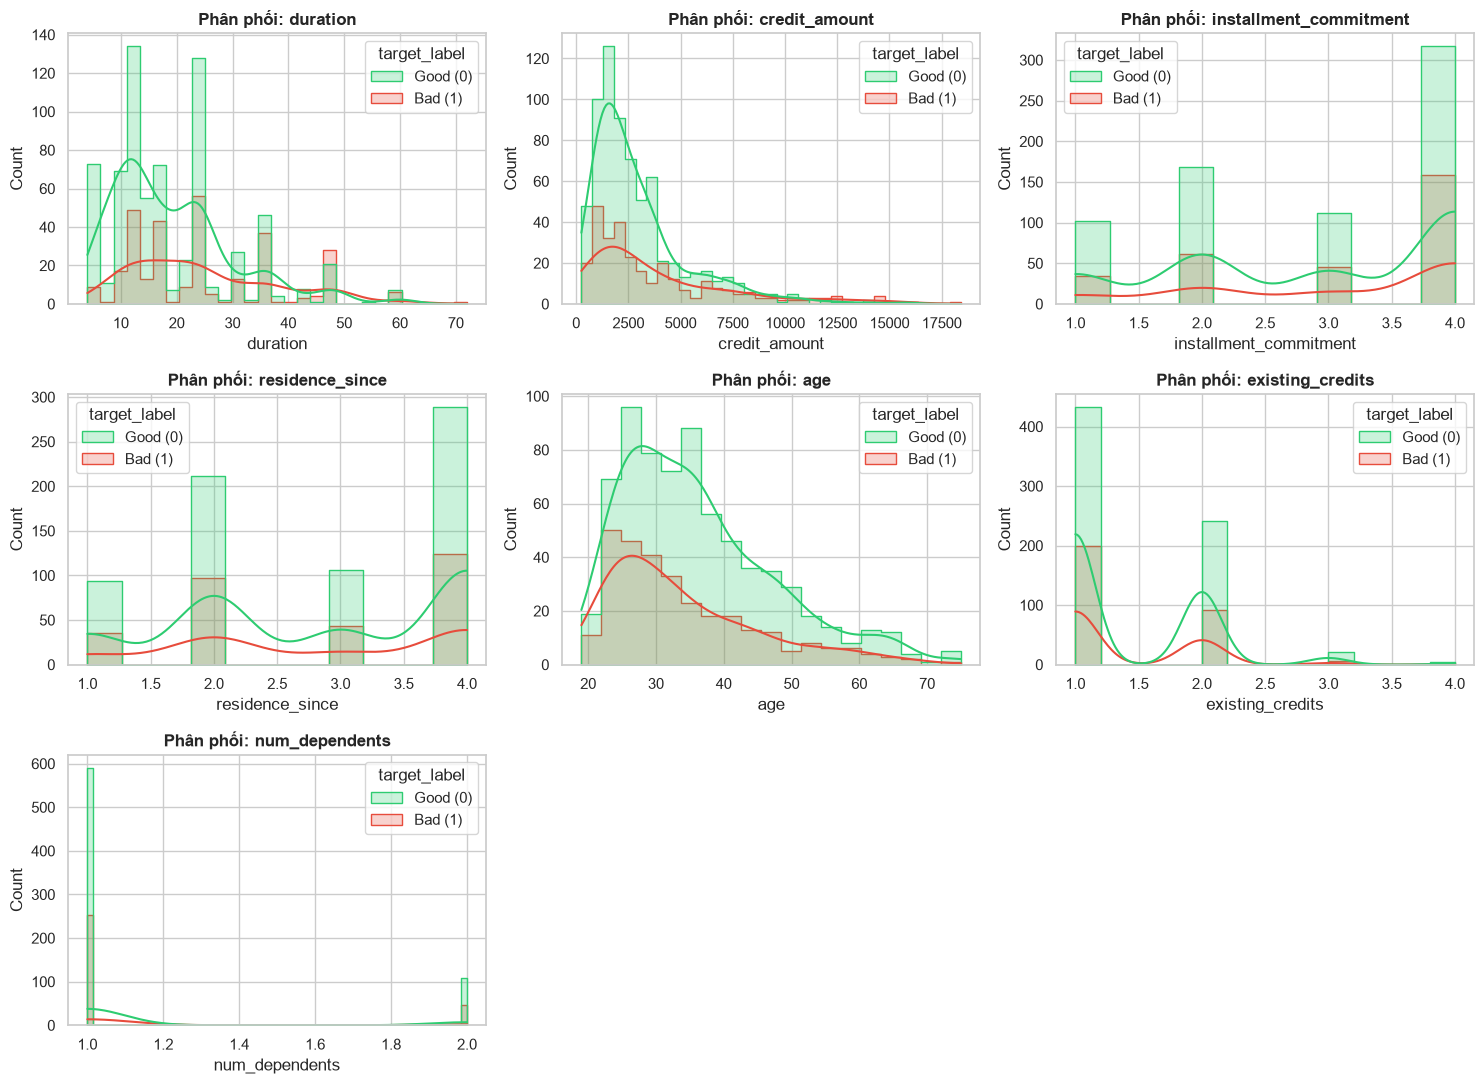

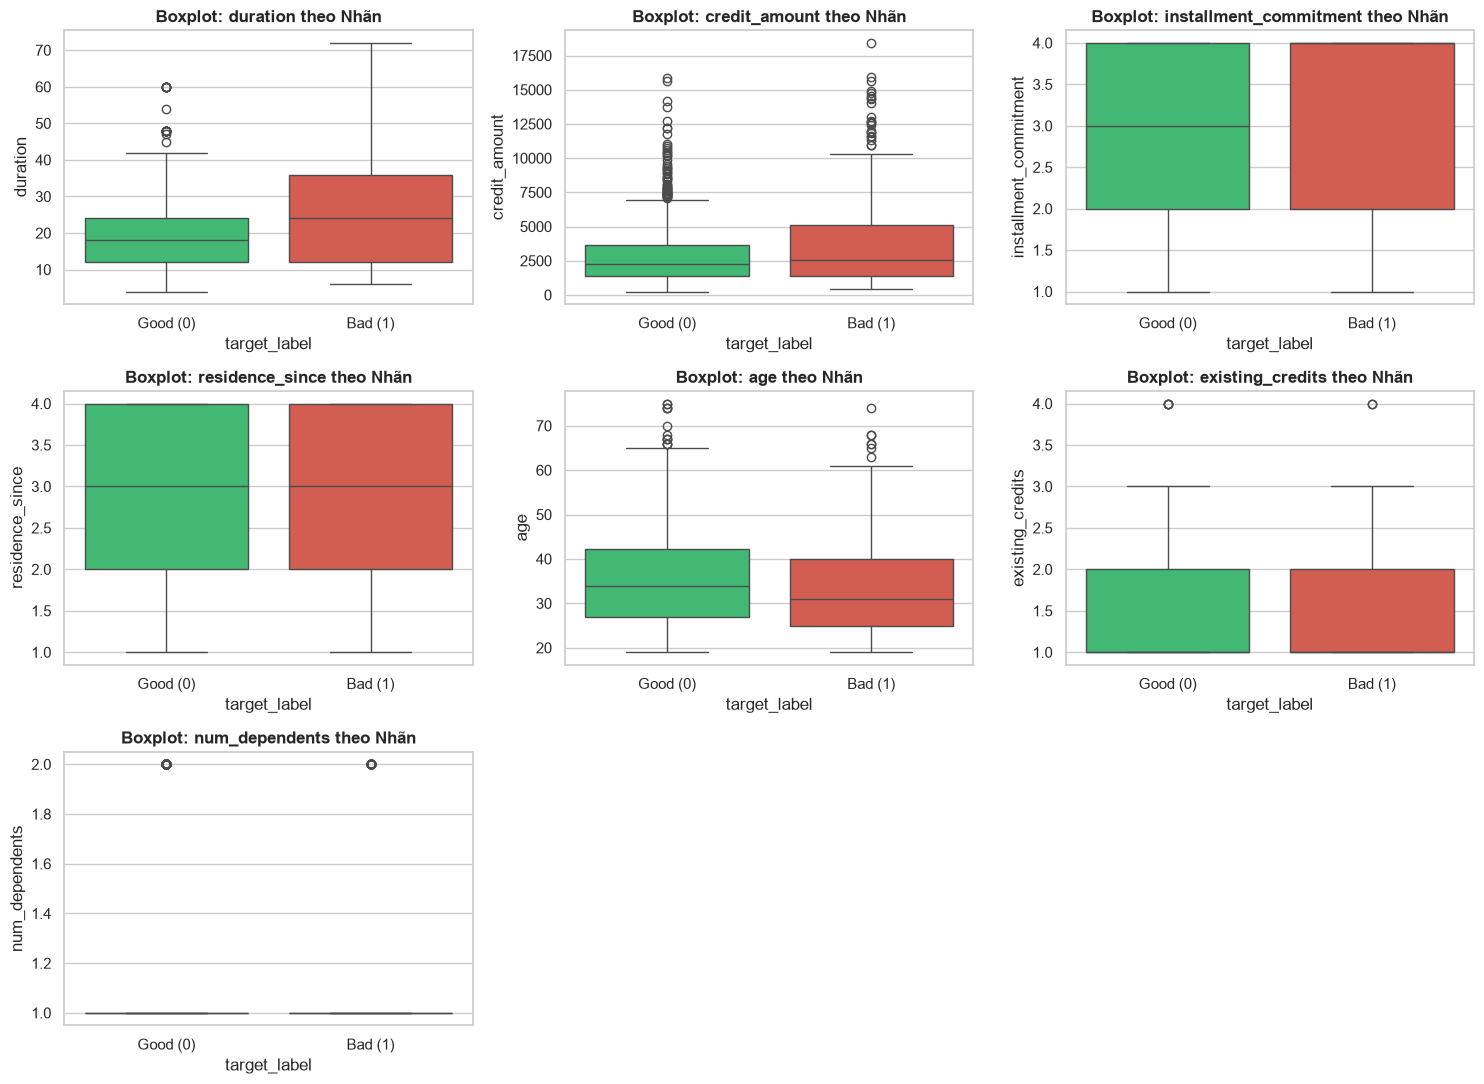

In [3]:
print("Thống kê mô tả 7 đặc trưng số:")
stats_df = df_raw[NUMERICAL_COLS].describe().T
stats_df["skewness"] = df_raw[NUMERICAL_COLS].skew()
display(stats_df)

# 1. Vẽ Histogram kèm đường KDE
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
for i, col in enumerate(NUMERICAL_COLS):
    sns.histplot(data=df_eda, x=col, hue="target_label", kde=True, ax=axes[i], palette=["#2ecc71", "#e74c3c"], element="step")
    axes[i].set_title(f"Phân phối: {col}", fontweight="bold")
for j in range(len(NUMERICAL_COLS), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_numerical_histograms.png", dpi=300)
plt.show()

# 2. Vẽ Boxplot phát hiện ngoại lệ theo từng lớp mục tiêu
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
for i, col in enumerate(NUMERICAL_COLS):
    sns.boxplot(data=df_eda, x="target_label", y=col, hue="target_label", ax=axes[i], palette=["#2ecc71", "#e74c3c"], legend=False)
    axes[i].set_title(f"Boxplot: {col} theo Nhãn", fontweight="bold")
for j in range(len(NUMERICAL_COLS), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_numerical_boxplots.png", dpi=300)
plt.show()

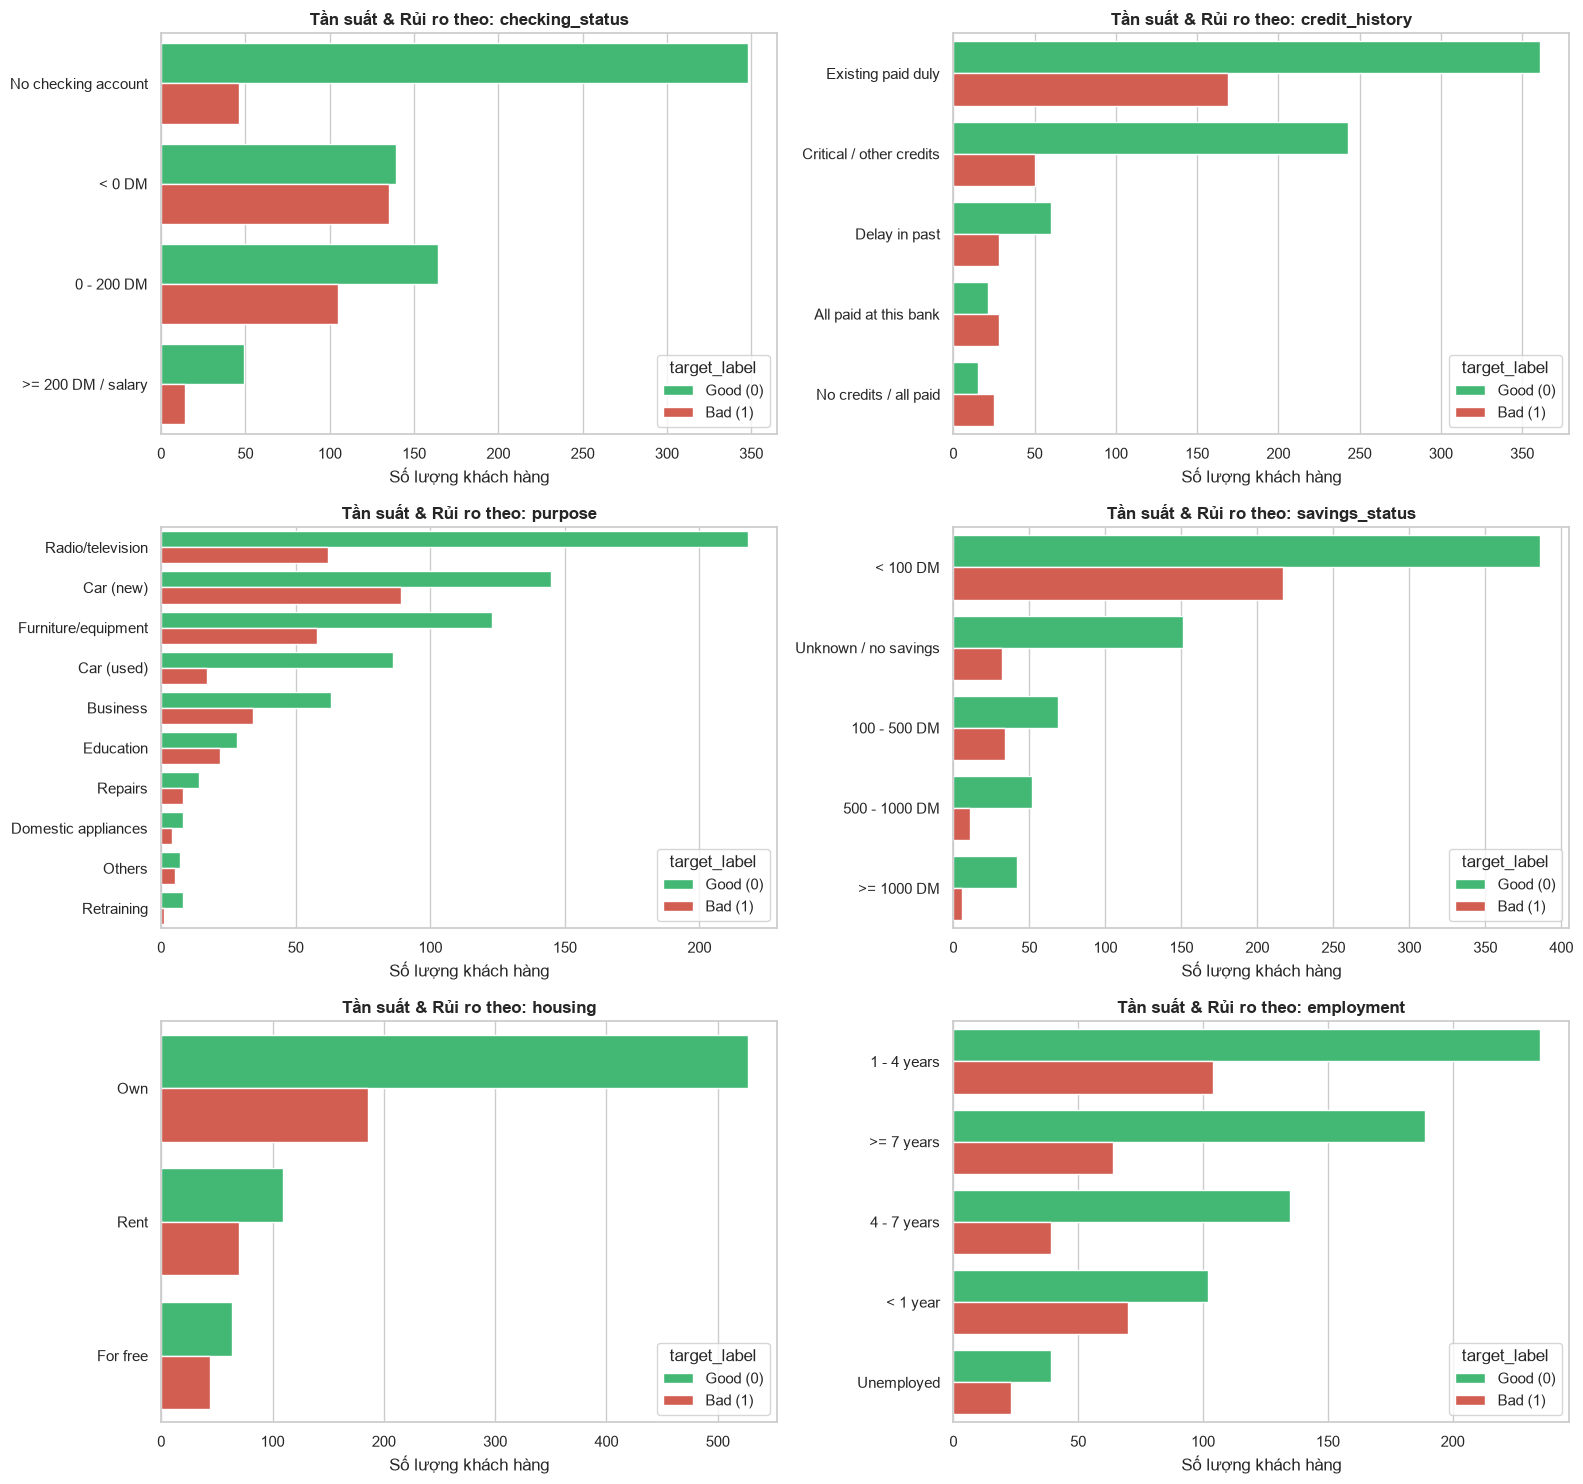


--- Tỷ lệ % theo checking_status ---


target_label,Bad (1),Good (0),Total_Count
checking_status,,,
< 0 DM,49.27,50.73,274
0 - 200 DM,39.03,60.97,269
>= 200 DM / salary,22.22,77.78,63
No checking account,11.68,88.32,394



--- Tỷ lệ % theo credit_history ---


target_label,Bad (1),Good (0),Total_Count
credit_history,,,
No credits / all paid,62.50,37.50,40
All paid at this bank,57.14,42.86,49
Existing paid duly,31.89,68.11,530
Delay in past,31.82,68.18,88
Critical / other credits,17.06,82.94,293



--- Tỷ lệ % theo purpose ---


target_label,Bad (1),Good (0),Total_Count
purpose,,,
Education,44.00,56.00,50
Others,41.67,58.33,12
Car (new),38.03,61.97,234
Repairs,36.36,63.64,22
Business,35.05,64.95,97
Domestic appliances,33.33,66.67,12
Furniture/equipment,32.04,67.96,181
Radio/television,22.14,77.86,280
Car (used),16.50,83.50,103


... (16 outputs left out)


--- Tỷ lệ % theo own_telephone ---


target_label,Bad (1),Good (0),Total_Count
own_telephone,,,
None,31.38,68.62,596
Yes (registered),27.97,72.03,404



--- Tỷ lệ % theo foreign_worker ---


target_label,Bad (1),Good (0),Total_Count
foreign_worker,,,
Yes,30.74,69.26,963
No,10.81,89.19,37


In [4]:
key_cat_cols = ["checking_status", "credit_history", "purpose", "savings_status", "housing", "employment"]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for i, col in enumerate(key_cat_cols):
    order = df_eda[col].value_counts().index
    sns.countplot(data=df_eda, y=col, hue="target_label", order=order, ax=axes[i], palette=["#2ecc71", "#e74c3c"])
    axes[i].set_title(f"Tần suất & Rủi ro theo: {col}", fontweight="bold")
    axes[i].set_xlabel("Số lượng khách hàng")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_categorical_bars.png", dpi=300)
plt.show()

# Bảng tỷ lệ nợ xấu (Bad Rate) của toàn bộ 13 biến phân loại
for col in CATEGORICAL_COLS:
    ct = pd.crosstab(df_eda[col], df_eda["target_label"], normalize="index") * 100
    ct["Total_Count"] = df_eda[col].value_counts()
    print(f"\n--- Tỷ lệ % theo {col} ---")
    display(ct.sort_values(by="Bad (1)", ascending=False).round(2))

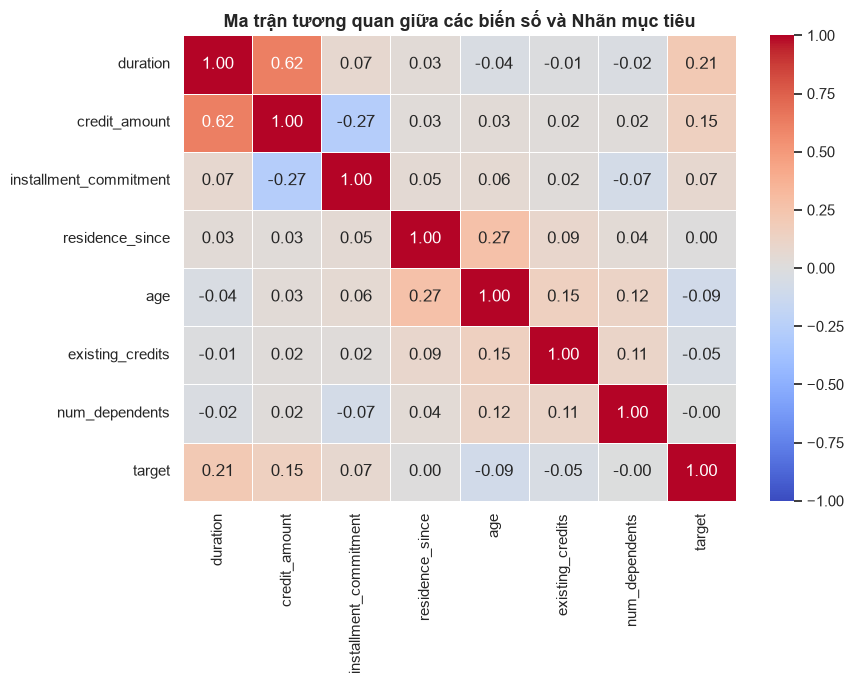

In [5]:
plt.figure(figsize=(9, 7))
corr_matrix = df_raw[NUMERICAL_COLS + ["target"]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Ma trận tương quan giữa các biến số và Nhãn mục tiêu", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_correlation_matrix.png", dpi=300)
plt.show()